# Credit card default - analysis

## Setup

In [59]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_default.config import load_config
from credit_default.data import DatasetLoader
#Baseline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, precision_score

from credit_default.features import build_preprocessor

CONFIG = load_config()
RANDOM_STATE = CONFIG["random_state"]
TARGET = CONFIG["target"]

pd.set_option("display.max_columns", 30)

## Part 1 · Load and inspect

In [35]:
loader = DatasetLoader()
df = loader.load_data()
print(df.shape)
print(df.dtypes)
df.head()

(30000, 25)
ID           int64
LIMIT_BAL    int64
SEX          int64
EDUCATION    int64
MARRIAGE     int64
AGE          int64
PAY_0        int64
PAY_2        int64
PAY_3        int64
PAY_4        int64
PAY_5        int64
PAY_6        int64
BILL_AMT1    int64
BILL_AMT2    int64
BILL_AMT3    int64
BILL_AMT4    int64
BILL_AMT5    int64
BILL_AMT6    int64
PAY_AMT1     int64
PAY_AMT2     int64
PAY_AMT3     int64
PAY_AMT4     int64
PAY_AMT5     int64
PAY_AMT6     int64
default      int64
dtype: object


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [36]:
# ✅ Check
assert df.shape == (30000, 25), df.shape
assert TARGET in df.columns
print("OK")

OK


Target: `default` (1 = default next month). `ID` is a row number, not a feature. The file has `PAY_0` then `PAY_2` (no `PAY_1`); we keep the original names.

## Part 2 · Explore

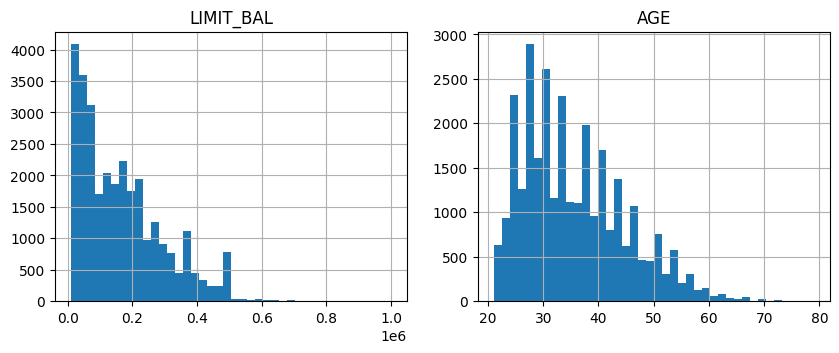

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,-0.291100,51223.330900,49179.075167,4.701315e+04,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,1.149988,73635.860576,71173.768783,6.934939e+04,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-165580.000000,-69777.000000,-1.572640e+05,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,3558.750000,2984.750000,2.666250e+03,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22381.500000,21200.000000,2.008850e+04,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67091.000000,64006.250000,6.016475e+04,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,964511.000000,983931.000000,1.664089e+06,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [41]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df["LIMIT_BAL"].hist(bins=40, ax=ax[0]); ax[0].set_title("LIMIT_BAL")
df["AGE"].hist(bins=40, ax=ax[1]); ax[1].set_title("AGE")
plt.show()
df.describe()

In [42]:
print(df["SEX"].value_counts().sort_index())
print(df["EDUCATION"].value_counts().sort_index())
print(df["MARRIAGE"].value_counts().sort_index())

PAY_COLS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL_COLS = ["BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"]

n_bad_edu = df["EDUCATION"].isin([0, 5, 6]).sum()
n_bad_mar = (df["MARRIAGE"] == 0).sum()
share_neg_bill = (df[BILL_COLS] < 0).any(axis=1).mean()
print(f"EDUCATION 0/5/6: {n_bad_edu} rows · MARRIAGE 0: {n_bad_mar} rows · {share_neg_bill:.1%} have a negative bill")
print("PAY values:", np.unique(df[PAY_COLS]))

SEX
1    11888
2    18112
Name: count, dtype: int64
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64
EDUCATION 0/5/6: 345 rows · MARRIAGE 0: 54 rows · 6.4% have a negative bill
PAY values: [-2 -1  0  1  2  3  4  5  6  7  8]


In [43]:
# ✅ Check
assert n_bad_edu == 345 and n_bad_mar == 54
print("OK")

OK


`EDUCATION` 0, 5, 6 and `MARRIAGE` 0 are undocumented codes. Negative bills are real (overpayment) and kept. `PAY_` columns are ordered delays (−2 to 8), kept numeric. `SEX`, `EDUCATION`, `MARRIAGE` are labels, one-hot encoded.

In [45]:
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(3))

default
0    23364
1     6636
Name: count, dtype: int64
default
0    0.779
1    0.221
Name: proportion, dtype: float64


22.1% default next month


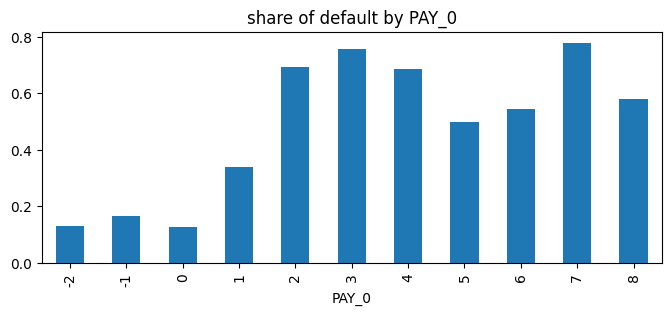

In [46]:
is_default = df[TARGET] == 1
rate_default = is_default.mean()
print(f"{rate_default:.1%} default next month")
is_default.groupby(df["PAY_0"]).mean().plot.bar(figsize=(8, 3), title="share of default by PAY_0")
plt.show()

In [47]:
# ✅ Check
assert set(df[TARGET].unique()) == {0, 1}
assert 0.2 < rate_default < 0.25
print("OK")

OK


22.1 % of clients default: "always no" gets 77.9 % accuracy, so accuracy is not the right metric. Default rate goes from about 13 % (`PAY_0` ≤ 0) to 69 % (2 months of delay).

## Part 3 · Clean

In [48]:
print(df.dtypes.value_counts())
print("missing values", df.isna().sum().sum())
print("duplicated rows", df.duplicated().sum())
print("duplicated rows without ID", df.drop(columns="ID").duplicated().sum())

int64    25
Name: count, dtype: int64
missing values 0
duplicated rows 0
duplicated rows without ID 35


In [49]:
df_clean = loader.clean(df)
print(df_clean["EDUCATION"].value_counts().sort_index())
print(df_clean["MARRIAGE"].value_counts().sort_index())
print(df_clean.shape)

EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64
(30000, 25)


In [50]:
# ✅ Check
assert set(df_clean["EDUCATION"].unique()) == {1, 2, 3, 4}
assert set(df_clean["MARRIAGE"].unique()) == {1, 2, 3}
assert len(df_clean) == len(df)
print("OK")

OK


No missing values. The 35 duplicates only appear without `ID` (different clients, same profile): kept. `EDUCATION` 0/5/6 → 4 and `MARRIAGE` 0 → 3 ("others"). No feature is known after the predicted month, so no leakage. `SEX`, `AGE`, `MARRIAGE` are sensitive attributes.

## Part 4 · Baseline

In [51]:
X_train, X_test, y_train, y_test = loader.split(df_clean)
print(X_train.shape, X_test.shape, "share of default · train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

(24000, 24) (6000, 24) share of default · train: 0.221 | test: 0.221


In [52]:
# ✅ Check
assert abs(len(X_test) / len(df_clean) - 0.2) < 0.01
assert abs(y_train.mean() - y_test.mean()) < 0.01
print("OK")

OK


In [60]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "average_precision": "average_precision"}

In [63]:
candidates = {"dummy (always no)": DummyClassifier(strategy="most_frequent"),
              "logistic regression": LogisticRegression(max_iter=1000)}
rows = {}
for name, clf in candidates.items():
    out = cross_validate(Pipeline([("prep", build_preprocessor()), ("clf", clf)]), X_train, y_train, cv=cv, scoring=SCORING)
    rows[name] = {s: out[f"test_{s}"].mean() for s in SCORING}
results = pd.DataFrame(rows).T.round(3)
results

C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,accuracy,precision,recall,f1,roc_auc,average_precision
dummy (always no),0.779,0.000,0.000,0.000,0.500,0.221
logistic regression,0.811,0.711,0.246,0.365,0.727,0.507


In [64]:
# ✅ Check
assert list(results.columns) == list(SCORING) and len(results) == 2
assert results.loc["logistic regression", "roc_auc"] > results.loc["dummy (always no)", "roc_auc"]
print("OK")

OK


Baseline under 5-fold stratified CV on the training set. "Always no" gets 0.779 accuracy but 0 recall: it never finds a defaulter. Logistic regression only adds 3 points of accuracy, but finds 25 % of the defaulters (recall 0.246) and ranks clients much better (ROC-AUC 0.727 vs 0.5, average precision 0.507 vs 0.221). Accuracy hides this, so we compare models on average precision and choose the threshold later.